# Amplitude field across the feature space

Visualizes the non-stationary amplitude proposed for asymmetric generalization (see `asymmetry.qmd`):

$$\log \sigma(x) = \log \sigma_0 + w^\top x / s, \qquad K = \mathrm{diag}(\sigma)\, R_\ell\, \mathrm{diag}(\sigma)$$

- $x$: 2D feature coordinates (already centred at 0).
- $s$: pooled SD of the coordinates over the whole feature set. It is fixed, not fit, so $w = 1$ means σ changes by a factor of $e$ per SD of the space.
- $w \in \mathbb{R}^2$: the direction σ increases in; $|w|$ sets how steeply. $w = 0$ is the current stationary model.
- $\sigma_0 = 0.522$ and $\mu_0 = 1.293$: study 9 ZOIB posterior medians.

How strongly evidence at a source $x'$ spreads to a target $x$ is $\rho(x, x') \cdot \sigma(x)/\sigma(x')$.

typical kernel:
$$k(x_i, x_j) = \sigma^2 e^{\frac{-||x_i-x_j||^2}{2\ell^2}}$$

asymmetric generalization kernel:
$$k(x_i, x_j) = \sigma_{ij}^2 e^{\frac{-||x_i-x_j||^2}{2\ell^2}}$$
(i.e., $\sigma_{ij}^2$ now depends on the locations of feature $i$ and feature $j$, and is no longer a constant)

we can parameterize the possibilities of how $\sigma_{ij}$ should vary across the space in a lot of ways. one is the following:

$$\sigma_j = \sigma_0e^{\frac{w_1x_1+w_2x_2}{s}}$$
where 
$x$ are the locations of feature $j$ in the 2d semantic space  
$w$ are fitted weights that operate along the two axes of the semantic space  
and $s$ is a constant that helps normalize with respect to the specific range of the coordinate space  
and $\sigma_0$ is a prior over the possible amplitudes (might initialize that to the current fitted $\sigma$?)  

another way to write it is:
$$\sigma_j = \sigma_0e^{\frac{w^{\top}x}{s}}$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import plot_style
plot_style.use_lexend()

SIGMA0 = 0.522   # study 9 ZOIB posterior median output_scale
MU0 = 1.293      # study 9 ZOIB posterior median mu_0

def load_set(name):
    df = pd.read_pickle(f'../features/{name}_features_dataframe.pkl')
    X = df[['x_2d', 'y_2d']].values
    s = float(np.sqrt(np.mean((X - X.mean(0)) ** 2)))   # pooled SD over both axes
    return df, X, s

def amp(X, w, s, sigma0=None):
    sigma0 = SIGMA0 if sigma0 is None else sigma0
    return sigma0 * np.exp(np.asarray(X) @ np.asarray(w, dtype=float) / s)

sets = {name: load_set(name) for name in ['set2', 'set1']}
for name, (df, X, s) in sets.items():
    print(f'{name}: {len(df)} features, mean {X.mean(0).round(3)}, pooled s = {s:.3f}')

set2: 60 features, mean [-0.  0.], pooled s = 0.197
set1: 32 features, mean [-0.  0.], pooled s = 0.196


In [2]:
CAT_COLORS = {
    'physical': 'tab:red', 'diet_preferences': 'tab:green', 'personality_behaviors': 'tab:blue',
    'hobbies_behaviors': 'tab:blue',   # set1's behaviour category, coloured like personality
    'abilities': 'tab:purple', 'appearance': 'tab:pink', 'beliefs_culture': 'tab:brown',
    'habitat': 'tab:olive',
}
# display order: physical, diet, personality first; any other (set1) categories after
CAT_ORDER = ['physical', 'diet_preferences', 'personality_behaviors', 'hobbies_behaviors',
             'abilities', 'appearance', 'beliefs_culture', 'habitat']
cat_rank = lambda c: CAT_ORDER.index(c) if c in CAT_ORDER else len(CAT_ORDER)
CAT_SHORT = {'diet_preferences': 'diet', 'personality_behaviors': 'personality',
             'hobbies_behaviors': 'hobbies', 'beliefs_culture': 'beliefs'}
short = lambda c: CAT_SHORT.get(c, c)

def grid_for(X, pad=0.08, n=200):
    lo, hi = X.min(0) - pad, X.max(0) + pad
    gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], n), np.linspace(lo[1], hi[1], n))
    return gx, gy, np.column_stack([gx.ravel(), gy.ravel()])

def draw_field(ax, df, X, s, w, norm, gx, gy, G, arrow=True):
    S = amp(G, w, s).reshape(gx.shape)
    im = ax.pcolormesh(gx, gy, S, norm=norm, cmap='viridis', shading='auto')
    if np.linalg.norm(w) > 0:
        levels = SIGMA0 * np.exp(np.arange(-6, 7) * 0.5)   # contours every factor of e^0.5
        ax.contour(gx, gy, S, levels=levels, colors='white', linewidths=0.6, alpha=0.6)
    for cat, sub in df.groupby('category'):
        for split, marker in [('train', 'o'), ('test', '^')]:
            pts = sub[sub.split == split][['x_2d', 'y_2d']].values
            if len(pts):
                ax.scatter(pts[:, 0], pts[:, 1], marker=marker, s=26 if split == 'train' else 46,
                           c=CAT_COLORS.get(cat, 'grey'), edgecolors='white', linewidths=0.7, zorder=3)
    if arrow and np.linalg.norm(w) > 0:
        d = np.asarray(w) / np.linalg.norm(w) * 0.25
        ax.annotate('', xy=d, xytext=(0, 0), zorder=4,
                    arrowprops=dict(arrowstyle='-|>', color='white', lw=2))
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    return im

def legend_handles(df):
    from matplotlib.lines import Line2D
    h = [Line2D([], [], marker='o', ls='', color=CAT_COLORS.get(c, 'grey'), label=short(c))
         for c in sorted(df.category.unique(), key=cat_rank)]
    h += [Line2D([], [], marker='o', ls='', color='k', mfc='none', label='train'),
          Line2D([], [], marker='^', ls='', color='k', mfc='none', label='test')]
    return h

## Grid of $w$ values (set2, study 9)

Rows: the steepness $|w|$. Columns: the direction of $w$, pointing at each category's centroid (σ is **highest** in that category), **away from physical** (σ is **lowest** at physical), or along the x-axis.

**Away from physical** encodes the causal hypothesis that physical features cause diet and personality features. Physical features are low-σ (stable) sources, so evidence about them spreads strongly to the high-σ diet and personality features, and the reverse spread is weak. Because the three centroids aren't collinear with the origin, diet and personality don't get exactly equal σ under this direction (diet ends up with the higher σ). The colour scale is shared and logarithmic. White lines are contours of σ, one per factor of $e^{0.5}$. They are always straight and parallel, because log σ is a tilted plane.

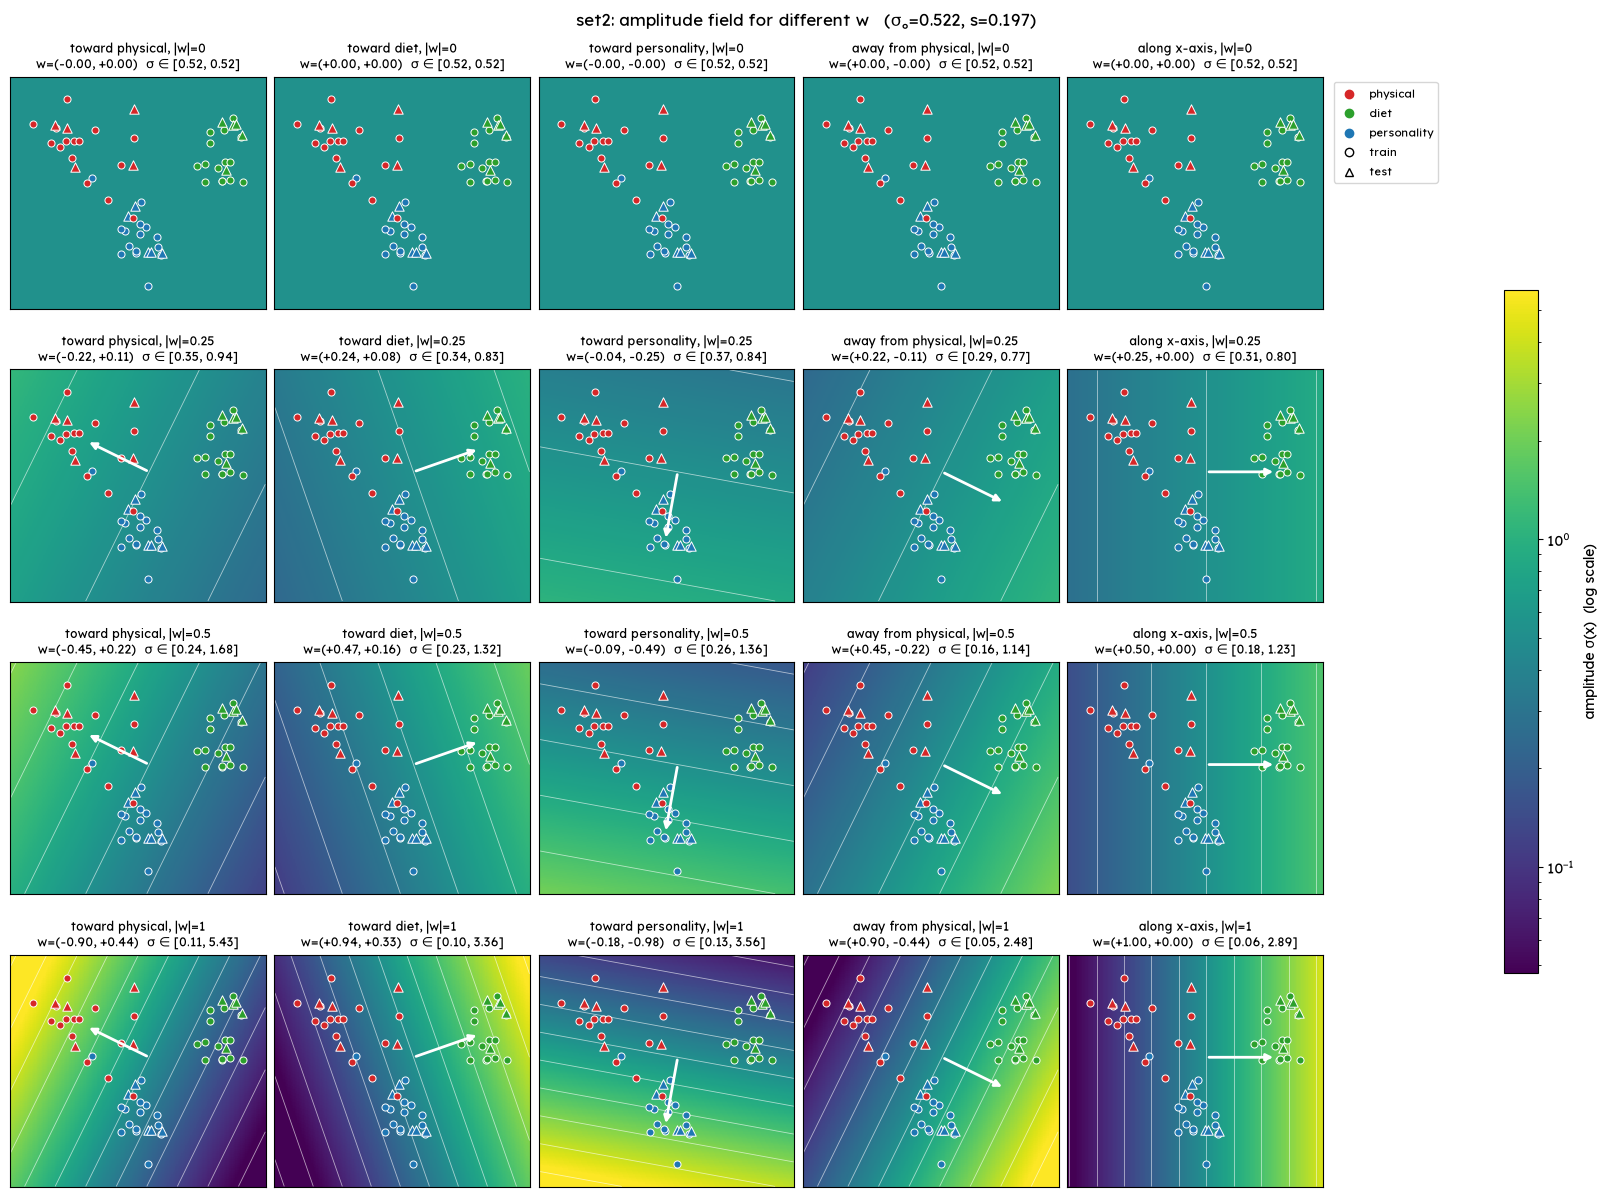

In [3]:
def direction_columns(df, X):
    cols = {}
    for cat in ['physical', 'diet_preferences', 'personality_behaviors']:
        if cat in set(df.category):
            c = df.loc[df.category == cat, ['x_2d', 'y_2d']].values.mean(0)
            cols[f'toward {short(cat)}'] = c / np.linalg.norm(c)
    if 'toward physical' in cols:
        # causal hypothesis: physical causes diet/personality -> sigma lowest at physical
        cols['away from physical'] = -cols['toward physical']
    cols['along x-axis'] = np.array([1.0, 0.0])
    return cols

def plot_w_grid(name, mags=(0, 0.25, 0.5, 1.0), directions=None):
    df, X, s = sets[name]
    gx, gy, G = grid_for(X)
    dirs = directions or direction_columns(df, X)
    norm = LogNorm(vmin=SIGMA0 * np.exp(-4 * max(mags) * 0.6), vmax=SIGMA0 * np.exp(4 * max(mags) * 0.6))
    fig, axes = plt.subplots(len(mags), len(dirs), figsize=(3.2 * len(dirs), 3.0 * len(mags)),
                             constrained_layout=True)
    for i, m in enumerate(mags):
        for j, (dname, u) in enumerate(dirs.items()):
            w = m * u
            im = draw_field(axes[i, j], df, X, s, w, norm, gx, gy, G)
            S_feat = amp(X, w, s)
            axes[i, j].set_title(f'{dname}, |w|={m:g}\nw=({w[0]:+.2f}, {w[1]:+.2f})  '
                                 f'σ ∈ [{S_feat.min():.2f}, {S_feat.max():.2f}]', fontsize=9)
    fig.colorbar(im, ax=axes, shrink=0.6, label='amplitude σ(x)  (log scale)')
    axes[0, -1].legend(handles=legend_handles(df), loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
    fig.suptitle(f'{name}: amplitude field for different w   (σ₀={SIGMA0}, s={s:.3f})')
    plt.show()

plot_w_grid('set2')

## How σ(x) reshapes prior prevalence

For each study 9 test feature: the prior ±1 SD band of coherence, $\mathrm{sigmoid}(\mu_0 \pm \sigma_j)$, before any statements. The dot marks $\mathrm{sigmoid}(\mu_0)$. High-σ features get a wider band, pushed toward 0 and 1; low-σ features stay near the base rate.

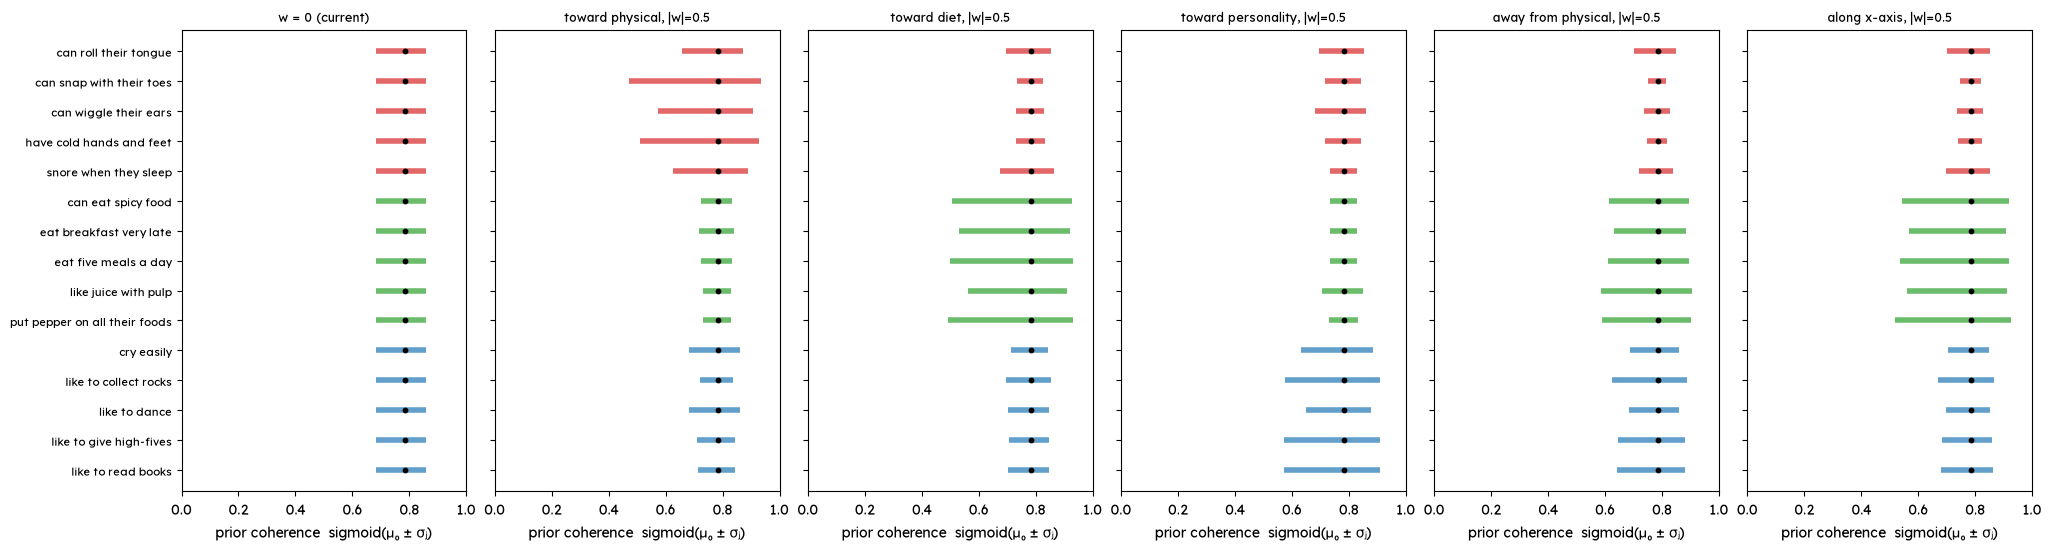

In [4]:
def plot_prior_bands(name='set2', m=0.5):
    df, X, s = sets[name]
    test = df[df.split == 'test']
    test = test.assign(_r=test.category.map(cat_rank)).sort_values(['_r', 'feature'])
    Xt = test[['x_2d', 'y_2d']].values
    dirs = {'w = 0 (current)': np.zeros(2), **{k: m * u for k, u in direction_columns(df, X).items()}}
    sig = lambda v: 1 / (1 + np.exp(-v))
    fig, axes = plt.subplots(1, len(dirs), figsize=(3.4 * len(dirs), 0.28 * len(test) + 1.2),
                             sharey=True, constrained_layout=True)
    ypos = np.arange(len(test))
    for ax, (dname, w) in zip(axes, dirs.items()):
        a = amp(Xt, w, s)
        cols = [CAT_COLORS.get(c, 'grey') for c in test.category]
        ax.hlines(ypos, sig(MU0 - a), sig(MU0 + a), colors=cols, lw=4, alpha=0.7)
        ax.scatter(np.full(len(test), sig(MU0)), ypos, c='k', s=10, zorder=3)
        ax.set_xlim(0, 1); ax.set_title(f'{dname}' + ('' if dname.startswith('w = 0') else f', |w|={m}'),
                                        fontsize=9)
        ax.set_xlabel('prior coherence  sigmoid(μ₀ ± σⱼ)')
    axes[0].set_yticks(ypos); axes[0].set_yticklabels(test.feature, fontsize=8); axes[0].invert_yaxis()
    plt.show()

plot_prior_bands('set2', m=0.5)

## Interactive: pick your own $w$

Uses ipywidgets sliders if they're available. The compgenerics env doesn't have it right now, so the cell falls back to a plain function: call `show_field(w1, w2, name='set2', sigma0=SIGMA0)` with any values.

ipywidgets not installed; static fallback (call show_field(w1, w2) with other values):


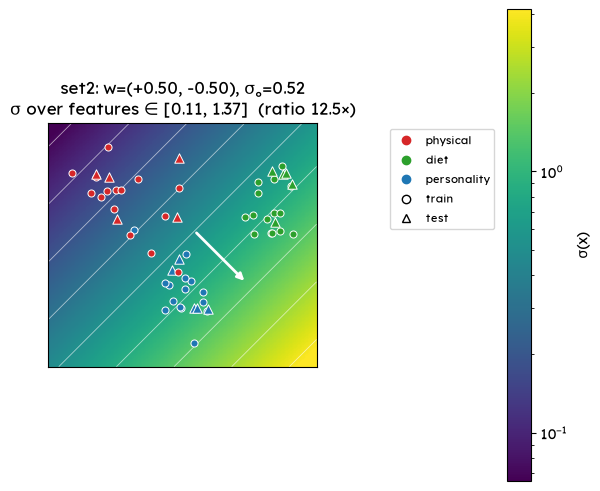

In [5]:
def show_field(w1=0.5, w2=0.0, name='set2', sigma0=SIGMA0):
    global SIGMA0
    old, SIGMA0 = SIGMA0, sigma0
    try:
        df, X, s = sets[name]
        w = np.array([w1, w2], dtype=float)
        gx, gy, G = grid_for(X)
        fig, ax = plt.subplots(figsize=(5.5, 4.8), constrained_layout=True)
        norm = LogNorm(vmin=sigma0 / 8, vmax=sigma0 * 8)
        im = draw_field(ax, df, X, s, w, norm, gx, gy, G)
        fig.colorbar(im, ax=ax, label='σ(x)')
        ax.legend(handles=legend_handles(df), loc='upper left', bbox_to_anchor=(1.25, 1), fontsize=8)
        S = amp(X, w, s)
        ax.set_title(f'{name}: w=({w1:+.2f}, {w2:+.2f}), σ₀={sigma0:.2f}\n'
                     f'σ over features ∈ [{S.min():.2f}, {S.max():.2f}]  (ratio {S.max() / S.min():.1f}×)')
        plt.show()
    finally:
        SIGMA0 = old

try:
    import ipywidgets as widgets
    widgets.interact(show_field,
                     w1=widgets.FloatSlider(value=0.5, min=-2, max=2, step=0.05),
                     w2=widgets.FloatSlider(value=0.0, min=-2, max=2, step=0.05),
                     name=['set2', 'set1'],
                     sigma0=widgets.FloatSlider(value=SIGMA0, min=0.1, max=2, step=0.05))
except ImportError:
    print('ipywidgets not installed; static fallback (call show_field(w1, w2) with other values):')
    show_field(0.5, -0.5)

## set1 (studies 6/8)

The same grid for set1. Columns point toward a few category centroids. Note that 15 of the 16 test features (▲) are `hobbies_behaviors`, clustered near the centre. So in studies 6/8, w mostly changes σ at the **train** features, i.e. how far each statement spreads, and not at the test features.

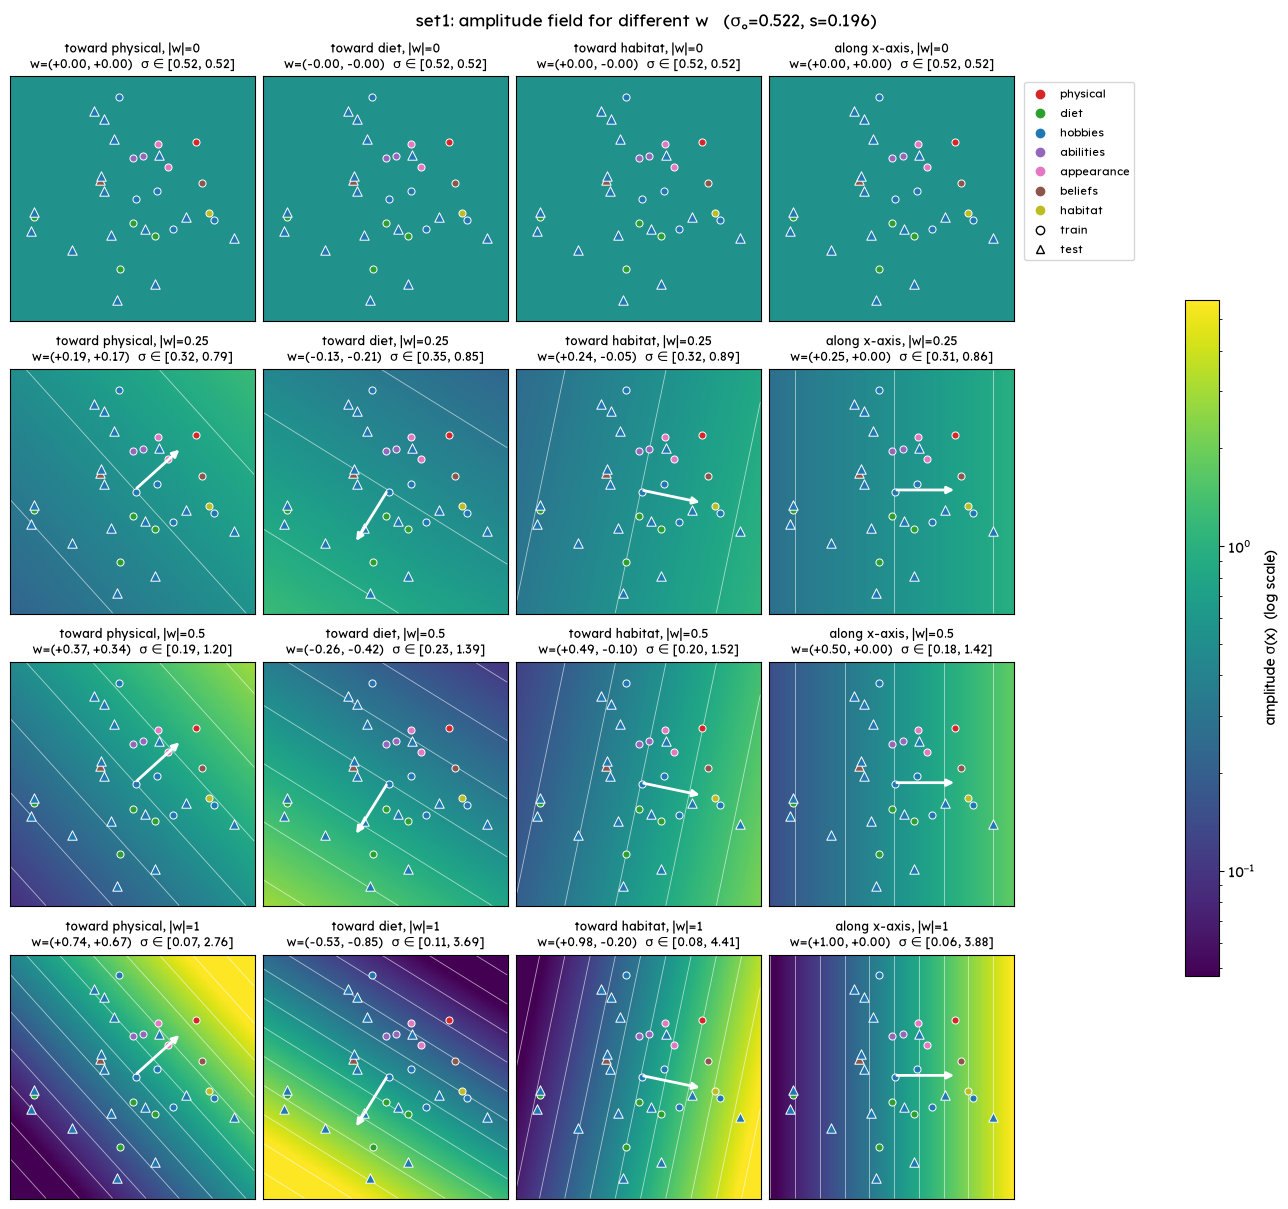

In [6]:
df1, X1, s1 = sets['set1']
dirs1 = {}
for cat in ['physical', 'diet_preferences', 'habitat']:
    c = df1.loc[df1.category == cat, ['x_2d', 'y_2d']].values.mean(0)
    dirs1[f'toward {short(cat)}'] = c / np.linalg.norm(c)
dirs1['along x-axis'] = np.array([1.0, 0.0])
plot_w_grid('set1', directions=dirs1)